# Vibrations of Water

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/temp/04-vibrations.ipynb)
:::


In [1]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB:
    if not Path("styles/tufte.mplstyle").exists():
        !wget -q -N -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
        !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py
    plt.style.use("styles/tufte.mplstyle")
    nproc = 2          # Colab gives you 2 cores
else:
    sys.path.insert(0, "..")                    # psi4_helpers.py is one folder up
    plt.style.use("../styles/tufte.mplstyle")
    nproc = 4          # house limit: 4 threads

import psi4_helpers as ph

# All Psi4 .out and .log files go into the output folder
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

# Resources: house limits are 4 threads and 4 GB
psi4.set_num_threads(nproc)
_ = psi4.set_memory("2 GB")


  Threads set to 4 by Python driver.



  Memory set to   1.863 GiB by Python driver.


Rock and roll! At a minimum on the potential energy surface, the curvature (second derivative) of the energy tells us how stiff each motion is. From the curvature and the atomic masses, *Psi4* calculates the **vibrational frequencies** and **normal modes**, which we can compare with the infrared spectrum.

## What You Will Learn
- How to run `psi4.frequency()` and read the frequencies, symmetries and IR intensities.
- How to **animate** the normal modes in the notebook.
- Why frequencies must be calculated at an optimized structure, **with the same method and basis set**.
- Why calculated (harmonic) frequencies are higher than the observed bands, and how **scale factors** are used.

Experimental values for water (cm⁻¹):

| Mode | Symmetry | Observed fundamental | Harmonic (from analysis of overtones) |
|---|---|---|---|
| bend, $\nu_2$ | $a_1$ | 1595 | 1649 |
| symmetric stretch, $\nu_1$ | $a_1$ | 3657 | 3832 |
| antisymmetric stretch, $\nu_3$ | $b_2$ | 3756 | 3943 |

In [2]:
psi4.set_output_file("output/04-vibrations.out", False);
psi4.set_options({"basis": "6-31g*", "scf_type": "pk"})

exp_fundamental = np.array([1595, 3657, 3756])
exp_harmonic    = np.array([1649, 3832, 3943])

## 1. Optimize, then Calculate Frequencies

```{note} Psi4 settings in this cell
:class: dropdown
`psi4.frequency("hf", molecule=water, return_wfn=True)`
: Calculates the **Hessian** (the matrix of second derivatives of the energy) and analyses it. For HF, *Psi4* computes the Hessian analytically. For methods without analytic second derivatives (most DFT functionals, MP2, CCSD(T)) it uses **finite differences** of gradients: it displaces the atoms a little in each direction and measures how the forces change. That takes several gradient calculations, so frequencies cost more than an optimization.

`dertype` (not set)
: Forces a choice: `dertype=0` uses finite differences of energies (slowest, but works for any method), `dertype=1` finite differences of gradients. *Psi4* chooses the best available automatically.

Same level for optimization and frequencies
: The harmonic analysis is only valid where the gradient is zero **for that method and basis set**. A structure optimized at a different level is not a stationary point at this level.
```

In [3]:
water = psi4.geometry("""
0 1
O
H 1 0.96
H 1 0.96 2 104.5
""")

psi4.optimize("hf", molecule=water)
E, wfn = psi4.frequency("hf", molecule=water, return_wfn=True)

freqs = wfn.frequencies().np
print("HF/6-31G* frequencies (cm-1):", ", ".join(f"{f:.1f}" for f in freqs))

Optimizer: Optimization complete!


HF/6-31G* frequencies (cm-1): 1825.9, 4069.8, 4188.5


The `frequency_analysis` dictionary holds much more: the symmetry of each mode, its IR intensity, its force constant and the displacement vectors. It includes all $3N = 9$ motions; the label `TRV` tells us which are **t**ranslations, **r**otations and **v**ibrations.

In [4]:
vib = wfn.frequency_analysis
is_vib = np.array([t == "V" for t in vib["TRV"].data])

table = pd.DataFrame({
    "frequency (cm-1)": vib["omega"].data[is_vib].real,
    "symmetry": np.array(vib["gamma"].data)[is_vib],
    "IR intensity (km/mol)": vib["IR_intensity"].data[is_vib],
    "force constant (mdyn/Å)": vib["k"].data[is_vib],
})
table.round(2)

,frequency (cm-1),symmetry,IR intensity (km/mol),force constant (mdyn/Å)
0,1825.86,A1,107.39,2.13
1,4069.81,A1,18.22,10.20
2,4188.53,B2,58.38,11.19


## 2. Animating the Normal Modes

*py3Dmol* can animate a vibration if we give it an $xyz$ string with a displacement vector after each atom's coordinates.

In [5]:
def show_mode(mol, vib, mode, amplitude=1.0):
    """Animate one vibrational mode (0 = lowest frequency) with py3Dmol."""
    is_vib = np.array([t == "V" for t in vib["TRV"].data])
    vectors = vib["x"].data[:, is_vib][:, mode].reshape(-1, 3)          # displacement for each atom
    xyz = mol.geometry().np * psi4.constants.bohr2angstroms
    lines = [str(mol.natom()), "mode"]
    for i in range(mol.natom()):
        x, y, z = xyz[i]
        dx, dy, dz = vectors[i]
        lines.append(f"{mol.symbol(i)} {x:.6f} {y:.6f} {z:.6f} {dx:.6f} {dy:.6f} {dz:.6f}")
    view = py3Dmol.view(width=300, height=250)
    view.addModel("\n".join(lines), "xyz", {"vibrate": {"frames": 10, "amplitude": amplitude}})
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    view.setBackgroundColor("#f2f2f2")
    view.zoomTo()
    view.animate({"loop": "backAndForth"})
    view.show()

for mode in range(3):
    print(f"Mode {mode + 1}: {table['frequency (cm-1)'][mode]:.0f} cm-1 ({table['symmetry'][mode]})")
    show_mode(water, vib, mode)

Mode 1: 1826 cm-1 (A1)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Mode 2: 4070 cm-1 (A1)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Mode 3: 4189 cm-1 (B2)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

The lowest mode is the **bend** (scissoring). The two higher modes are the **symmetric** stretch (both O–H bonds stretch together, $a_1$) and the **antisymmetric** stretch (one stretches while the other shrinks, $b_2$).

## 3. A Calculated IR Spectrum

The IR intensity measures how much the dipole moment changes during the vibration. We draw it as a stick spectrum.

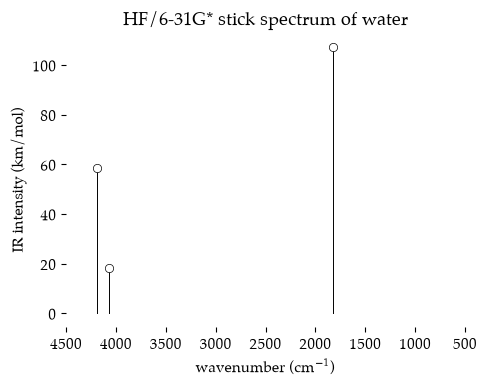

In [6]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
for f, I in zip(table["frequency (cm-1)"], table["IR intensity (km/mol)"]):
    ax.plot([f, f], [0, I], color="black", linewidth=0.7)
ax.plot(table["frequency (cm-1)"], table["IR intensity (km/mol)"], linestyle="none", marker="o",
        markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5)
ax.set_xlim(4500, 500)              # IR spectra are drawn with wavenumber decreasing
ax.set_xlabel(r"wavenumber (cm$^{-1}$)")
ax.set_ylabel("IR intensity (km/mol)")
ax.set_title("HF/6-31G* stick spectrum of water")
plt.show()

## 4. Comparing Levels of Effort

Calculated frequencies are **harmonic**: they assume each bond behaves like a perfect spring. Real bonds get weaker as they stretch (they are *anharmonic*), so observed fundamentals are lower. HF also makes bonds too stiff because it lacks electron correlation. Both errors make HF frequencies too high.

A common fix is to multiply calculated frequencies by an empirical **scale factor** fitted to many molecules, for example about 0.895 for HF/6-31G* and about 0.961 for B3LYP/6-31G* (Scott and Radom, *J. Phys. Chem.* **1996**, *100*, 16502). Scaled frequencies are compared with observed fundamentals.

```{note} Psi4 settings for the higher levels
:class: dropdown
`freeze_core: True` leaves the O 1s electrons uncorrelated in MP2 and CCSD(T) (see the *Level of Effort* notebook). `scf_type: "df"` speeds up the SCF part. For CCSD(T) the Hessian comes from finite differences of analytic gradients, which is why it is the slowest step in this notebook (about a minute on *Colab*).

*Alternatives:* `b3lyp/def2-tzvp` or `wb97x-d/def2-tzvp` (better DFT frequencies), `mp2/aug-cc-pvtz`. *Psi4* can also calculate anharmonic corrections only through external programs, so we rely on comparison with harmonic experimental values or on scaling.
```

In [7]:
import time

psi4.set_options({"scf_type": "df", "freeze_core": True})
levels = ["hf/6-31g*", "b3lyp/6-31g*", "mp2/cc-pvtz", "ccsd(t)/cc-pvtz"]

rows = []
for level in levels:
    mol = psi4.geometry("""
    0 1
    O
    H 1 0.96
    H 1 0.96 2 104.5
    """)
    t0 = time.perf_counter()
    psi4.optimize(level, molecule=mol)
    E, w = psi4.frequency(level, molecule=mol, return_wfn=True)
    f = np.sort(w.frequencies().np)
    rows.append({"level": level, "bend": f[0], "sym. stretch": f[1], "antisym. stretch": f[2],
                 "time (s)": time.perf_counter() - t0})

rows.append({"level": "experiment (harmonic)", "bend": 1649, "sym. stretch": 3832, "antisym. stretch": 3943})
rows.append({"level": "experiment (fundamental)", "bend": 1595, "sym. stretch": 3657, "antisym. stretch": 3756})
freq_table = pd.DataFrame(rows)
freq_table.round(0)

Optimizer: Optimization complete!


Optimizer: Optimization complete!


Optimizer: Optimization complete!


Optimizer: Optimization complete!


,level,bend,sym. stretch,antisym. stretch,time (s)
0,hf/6-31g*,1826.0,4070.0,4189.0,2.0
1,b3lyp/6-31g*,1713.0,3728.0,3849.0,5.0
2,mp2/cc-pvtz,1652.0,3856.0,3976.0,5.0
3,ccsd(t)/cc-pvtz,1669.0,3842.0,3946.0,31.0
4,experiment (harmonic),1649.0,3832.0,3943.0,NaN
5,experiment (fundamental),1595.0,3657.0,3756.0,NaN


Notice how HF overestimates every frequency by about 10 %. MP2 and CCSD(T) with the cc-pVTZ basis set come within a few tens of cm⁻¹ of the **harmonic** experimental values, yet they are still well above the **observed** bands. That remaining gap is anharmonicity, not an error in the method.

B3LYP/6-31G* lands *below* the harmonic values and closer to the observed bands. That is a lucky cancellation of errors, which is why its scale factor is close to 1.

## 5. A Common Mistake: Frequencies at the Wrong Structure

What happens if we calculate HF/6-31G* frequencies at a structure that was never optimized (or that was optimized at a different level)? The structure is no longer at the bottom of the HF/6-31G* energy surface, so the analysis is no longer valid.

In [8]:
psi4.set_options({"scf_type": "pk"})
not_optimized = psi4.geometry("""
0 1
O
H 1 1.00
H 1 1.00 2 110.0
""")
E, w = psi4.frequency("hf", molecule=not_optimized, return_wfn=True)
v = w.frequency_analysis
print("Unoptimized structure (cm-1):     ", ", ".join(f"{f:.1f}" for f in w.frequencies().np))
print("Optimized HF/6-31G* values (cm-1):", ", ".join(f"{f:.1f}" for f in freqs))

Unoptimized structure (cm-1):      767.8, 868.3, 909.4, 1869.6, 3366.2, 3501.5
Optimized HF/6-31G* values (cm-1): 1825.9, 4069.8, 4188.5


The stretches move by hundreds of cm⁻¹. Worse, three extra "vibrations" appear below 1000 cm⁻¹. At a structure where the forces are not zero, *Psi4* can no longer separate the **rotations** of the molecule from its vibrations, so the rotations show up as fake frequencies. Always **optimize first, at the same level**, and check that the optimization converged.

```{important} Imaginary frequencies
A true minimum has only real (positive) frequencies. An **imaginary** frequency (printed as a negative number or with an `i`) means the structure is at a **saddle point**: moving along that mode lowers the energy. That is what we want for a transition state, but for a stable molecule it means the optimization stopped in the wrong place. In the *Bending Scan* notebook we meet one: linear water.
```

## Summary
- `psi4.frequency()` gives frequencies, symmetries, IR intensities and normal modes.
- Calculate frequencies at a structure optimized with the **same method and basis set**.
- Calculated frequencies are harmonic; compare them with harmonic experimental values or scale them before comparing with observed bands.
- HF frequencies are about 10 % too high; correlated methods do much better.